In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_ROOT = '/content/drive/MyDrive/ecg_v3'   # everything we keep goes here
LOCAL_ROOT = '/content/genecg'                  # fast local Colab disk for downloading
REPO_ID    = 'edcci/GenECG'
SUBSET_A   = 'Dataset_A_ECGs_without_imperfections'
SUBSET_B   = 'Dataset_B_ECGs_with_imperfections'

B_TRAIN_SAMPLES = 3000   # photo-like training images to fetch (0 = skip)
B_MAX_SIDE      = 1600   # photo-like images are shrunk to this longest side
B_JPEG_QUALITY  = 90
N_WORKERS       = 16
SEED            = 42

os.makedirs(f'{DRIVE_ROOT}/labels', exist_ok=True)
os.makedirs(LOCAL_ROOT, exist_ok=True)
print('Drive folder ready:', DRIVE_ROOT)

# check free space on Drive and on the Colab disk
!df -h /content/drive/MyDrive | tail -1
!df -h /content | tail -1

Mounted at /content/drive
Drive folder ready: /content/drive/MyDrive/ecg_v3
drive            15G  137M   15G   1% /content/drive
overlay         113G   43G   71G  38% /


In [ ]:
import urllib.request
PTBXL = 'https://physionet.org/files/ptb-xl/1.0.3'
for f in ['ptbxl_database.csv', 'scp_statements.csv']:
    dst = f'{DRIVE_ROOT}/labels/{f}'
    if not os.path.exists(dst):
        urllib.request.urlretrieve(f'{PTBXL}/{f}', dst)
    print(f, os.path.getsize(dst) // 1024, 'KB')

ptbxl_database.csv 6440 KB
scp_statements.csv 9 KB


In [ ]:
import ast
import numpy as np
import pandas as pd

SUPER = ['NORM', 'MI', 'STTC', 'CD', 'HYP']

def build_labels(db, scp):
    # Standard PTB-XL mapping: diagnosis codes -> 5 groups
    diag = scp[scp.diagnostic == 1]
    db = db.copy()
    db['scp_codes'] = db.scp_codes.apply(ast.literal_eval)
    db['superclasses'] = db.scp_codes.apply(
        lambda codes: sorted({diag.loc[c, 'diagnostic_class'] for c in codes if c in diag.index}))
    for c in SUPER:
        db[c] = db.superclasses.apply(lambda s, c=c: int(c in s))
    # GenECG image names follow PTB-XL file names:
    # records500/02000/02000_hr  ->  02000/02000_hr_1R.png
    db['rel_path'] = db.filename_hr.str.replace('records500/', '', regex=False) + '_1R.png'
    keep = ['patient_id', 'age', 'sex', 'strat_fold', 'validated_by_human',
            'infarction_stadium1', 'infarction_stadium2', 'rel_path', 'superclasses'] + SUPER
    out = db[keep].copy()
    out['n_super'] = out[SUPER].sum(axis=1)
    return out

db  = pd.read_csv(f'{DRIVE_ROOT}/labels/ptbxl_database.csv', index_col='ecg_id')
scp = pd.read_csv(f'{DRIVE_ROOT}/labels/scp_statements.csv', index_col=0)
labels = build_labels(db, scp)
labels.to_csv(f'{DRIVE_ROOT}/labels/labels_genecg.csv')

print(len(labels), 'ECGs from', labels.patient_id.nunique(), 'patients')
print('\nECGs per class (one ECG can have several):')
print(labels[SUPER].sum().to_string())
print('\nECGs with no diagnosis group:', int((labels.n_super == 0).sum()))
print('\nPer official fold (1-8 train, 9 val, 10 test):')
print(labels.groupby('strat_fold')[SUPER].sum())
print('\nMI stage (for splitting MI into acute vs old later):')
print(labels.infarction_stadium1.value_counts(dropna=False).to_string())

21799 ECGs from 18869 patients

ECGs per class (one ECG can have several):
NORM    9514
MI      5469
STTC    5235
CD      4898
HYP     2649

ECGs with no diagnosis group: 411

Per official fold (1-8 train, 9 val, 10 test):
            NORM   MI  STTC   CD  HYP
strat_fold                           
1            940  549   526  481  263
2            967  538   524  485  264
3            991  528   515  487  264
4            927  551   527  494  261
5            939  563   532  496  265
6            930  562   528  494  270
7            970  550   520  478  264
8            932  538   514  492  268
9            955  540   528  495  268
10           963  550   521  496  262

MI stage (for splitting MI into acute vs old later):
infarction_stadium1
NaN               16187
unknown            3430
Stadium III         980
Stadium II-III      943
Stadium I           166
Stadium II           88
Stadium I-II          5


In [ ]:
import time
from huggingface_hub import snapshot_download

def list_pngs(root):
    return {os.path.relpath(os.path.join(r, f), root).replace(os.sep, '/')
            for r, _, fs in os.walk(root) for f in fs if f.endswith('.png')}

tar_A = f'{DRIVE_ROOT}/genecg_A.tar'
if os.path.exists(tar_A):
    print('genecg_A.tar already on Drive, skipping download.')
else:
    t = time.time()
    snapshot_download(repo_id=REPO_ID, repo_type='dataset', local_dir=LOCAL_ROOT,
                      allow_patterns=[f'{SUBSET_A}/*'], max_workers=N_WORKERS)
    files_A = list_pngs(f'{LOCAL_ROOT}/{SUBSET_A}')
    print(len(files_A), 'images downloaded in', round((time.time() - t) / 60, 1), 'min')
    missing_A = sorted(set(labels.rel_path) - files_A)
    print('label rows without an image:', len(missing_A), missing_A[:5])

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 21799 files:   0%|          | 0/21799 [00:00<?, ?it/s]

21799 images downloaded in 21.8 min
label rows without an image: 0 []


In [ ]:
if not os.path.exists(tar_A):
    !tar -cf "{tar_A}" -C "{LOCAL_ROOT}" "{SUBSET_A}"
!ls -lh "{tar_A}"

-rw------- 1 root root 2.3G Oct 30 22:25 /content/drive/MyDrive/ecg_v3/genecg_A.tar


In [ ]:
from huggingface_hub import login, hf_hub_download
from google.colab import userdata
login(token=userdata.get('HF_TOKEN'))
print('Logged in to Hugging Face')

from concurrent.futures import ThreadPoolExecutor, as_completed
from PIL import Image
import time

B_OUT = f'{LOCAL_ROOT}/B_jpg'
B_TMP = f'{LOCAL_ROOT}/tmpB'

def fetch_b(rel):
    # download one photo-like image, shrink it to JPEG, delete the big original
    out = os.path.join(B_OUT, rel[:-4] + '.jpg')
    if os.path.exists(out):
        return rel, 'skip', 0
    os.makedirs(os.path.dirname(out), exist_ok=True)
    try:
        p = hf_hub_download(REPO_ID, f'{SUBSET_B}/{rel}', repo_type='dataset', local_dir=B_TMP)
        size = os.path.getsize(p)
        im = Image.open(p).convert('RGB')
        im.thumbnail((B_MAX_SIDE, B_MAX_SIDE), Image.LANCZOS)
        im.save(out, quality=B_JPEG_QUALITY)
        os.remove(p)
        return rel, 'ok', size
    except Exception as e:
        return rel, f'error: {type(e).__name__}: {e}', 0

# speed test: 50 images from the test fold (10)
test_rel = labels[labels.strat_fold == 10].rel_path.iloc[:50].tolist()
t = time.time()
with ThreadPoolExecutor(N_WORKERS) as ex:
    results = [f.result() for f in as_completed([ex.submit(fetch_b, r) for r in test_rel])]
secs = time.time() - t

ok = [r for r in results if r[1] == 'ok']
errs = [r for r in results if r[1].startswith('error')]
mb = sum(r[2] for r in ok) / 1e6
print(f'{len(ok)} ok, {len(errs)} errors in {secs:.0f} s  ->  {mb/secs:.1f} MB/s, {len(ok)/secs*60:.0f} images/min')
for r in errs[:3]:
    print(' ', r[0], r[1])

per_min = max(len(ok) / secs * 60, 1e-6)
for n in [1000, 2180, 4360, 7360]:
    print(f'  {n:>5} images would take about {n/per_min:.0f} min')

sample = os.path.join(B_OUT, test_rel[0][:-4] + '.jpg')
if os.path.exists(sample):
    print('Saved JPEG size:', Image.open(sample).size, round(os.path.getsize(sample)/1e6, 2), 'MB')

Logged in to Hugging Face


Dataset_B_ECGs_with_imperfections/00000/(…): reconstructing file:   0%|          |  0.00B / 10.3MB            

Dataset_B_ECGs_with_imperfections/00000/(…): reconstructing file:   0%|          |  0.00B / 10.4MB            

Dataset_B_ECGs_with_imperfections/00000/(…): reconstructing file:   0%|          |  0.00B / 10.5MB            

Dataset_B_ECGs_with_imperfections/00000/(…): reconstructing file:   0%|          |  0.00B / 10.4MB            

Dataset_B_ECGs_with_imperfections/00000/(…): reconstructing file:   0%|          |  0.00B / 10.4MB            

... (92 outputs left out)

Dataset_B_ECGs_with_imperfections/00000/(…): reconstructing file:   0%|          |  0.00B / 10.2MB            

Dataset_B_ECGs_with_imperfections/00000/(…): downloading bytes:           |  0.00B            

Dataset_B_ECGs_with_imperfections/00000/(…): downloading bytes:           |  0.00B            

48 ok, 2 errors in 26 s  ->  19.0 MB/s, 111 images/min
  00000/00063_hr_1R.png error: RuntimeError: Task error: File size mismatch: expected 10617009 bytes but downloaded 10609296 bytes
  00000/00038_hr_1R.png error: RuntimeError: Task error: File size mismatch: expected 10401422 bytes but downloaded 10379790 bytes
   1000 images would take about 9 min
   2180 images would take about 20 min
   4360 images would take about 39 min
   7360 images would take about 66 min
Saved JPEG size: (1600, 879) 0.3 MB


In [ ]:
import numpy as np
from tqdm.auto import tqdm
from huggingface_hub.utils import disable_progress_bars
disable_progress_bars()   # stop the per-file progress spam

def fetch_b_retry(rel, tries=4):
    for attempt in range(tries):
        res = fetch_b(rel)
        if not res[1].startswith('error'):
            return res
        time.sleep(2 * (attempt + 1))   # short wait, then try again
    return res

# which B images to fetch
rng = np.random.default_rng(SEED)
eval_B  = labels[labels.strat_fold.isin([9, 10])]
train_B = labels[labels.strat_fold <= 8]
train_B = train_B.loc[np.sort(rng.choice(train_B.index, size=B_TRAIN_SAMPLES, replace=False))]
subset_B = pd.concat([eval_B, train_B]).sort_index()
subset_B.to_csv(f'{DRIVE_ROOT}/labels/subset_B.csv')
print(f'Photo-like images to fetch: {len(subset_B)} (val/test {len(eval_B)}, train {len(train_B)})')

t = time.time()
status = {}
with ThreadPoolExecutor(N_WORKERS) as ex:
    futs = [ex.submit(fetch_b_retry, r) for r in subset_B.rel_path]
    for f in tqdm(as_completed(futs), total=len(futs)):
        rel, s, _ = f.result()
        status[rel] = s

errors = {k: v for k, v in status.items() if v.startswith('error')}
done = sum(os.path.exists(os.path.join(B_OUT, r[:-4] + '.jpg')) for r in subset_B.rel_path)
print(f'finished in {(time.time()-t)/60:.0f} min | {done}/{len(subset_B)} JPEGs saved | {len(errors)} still failing')
for k, v in list(errors.items())[:5]:
    print(' ', k, v)

Photo-like images to fetch: 7381 (val/test 4381, train 3000)


  0%|          | 0/7381 [00:00<?, ?it/s]

finished in 50 min | 7378/7381 JPEGs saved | 3 still failing
  00000/00038_hr_1R.png error: RuntimeError: Task error: File size mismatch: expected 10401422 bytes but downloaded 10379790 bytes
  00000/00063_hr_1R.png error: RuntimeError: Task error: File size mismatch: expected 10617009 bytes but downloaded 10609296 bytes
  00000/00069_hr_1R.png error: RuntimeError: Task error: File size mismatch: expected 10459982 bytes but downloaded 10284670 bytes


In [ ]:
import shutil

# remove the 3 broken files from the B list and record them
failed = sorted(errors.keys())
subset_B = subset_B[~subset_B.rel_path.isin(failed)]
subset_B.to_csv(f'{DRIVE_ROOT}/labels/subset_B.csv')
pd.Series(failed, name='rel_path').to_csv(f'{DRIVE_ROOT}/labels/B_failed_downloads.csv', index=False)
print('Photo-like images kept:', len(subset_B))
print(subset_B.groupby('strat_fold').size().to_string())

# clean up leftover temporary downloads, then archive the JPEGs to Drive
shutil.rmtree(B_TMP, ignore_errors=True)
tar_B = f'{DRIVE_ROOT}/genecg_B_subset.tar'
!tar -cf "{tar_B}" -C "{LOCAL_ROOT}" B_jpg
!ls -lh "{tar_B}"

Photo-like images kept: 7378
strat_fold
1      370
2      391
3      384
4      356
5      375
6      387
7      360
8      377
9     2182
10    2196
-rw------- 1 root root 2.0G Oct 30 23:19 /content/drive/MyDrive/ecg_v3/genecg_B_subset.tar


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(SUPER), 2, figsize=(16, 4.5 * len(SUPER)))
for row, c in enumerate(SUPER):
    # pick an ECG with only this class, present in both A and B
    pool = subset_B[(subset_B[c] == 1) & (subset_B.n_super == 1)]
    rel = pool.rel_path.iloc[0]
    a_path = f'{LOCAL_ROOT}/{SUBSET_A}/{rel}'
    b_path = f'{B_OUT}/{rel[:-4]}.jpg'
    for col, (p, name) in enumerate([(a_path, 'A clean'), (b_path, 'B photo-like')]):
        axes[row, col].imshow(Image.open(p))
        axes[row, col].set_title(f'{c} | {name} | {rel}', fontsize=11)
        axes[row, col].axis('off')
plt.tight_layout()
plt.savefig(f'{DRIVE_ROOT}/samples_per_class.png', dpi=80)
plt.show()

with Image.open(a_path) as im:
    print('Clean image size:', im.size, '| mode:', im.mode)
with Image.open(b_path) as im:
    print('Photo-like image size:', im.size)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import collections
sizes_A, sizes_B = collections.Counter(), collections.Counter()
for rel in subset_B.rel_path.iloc[:200]:
    with Image.open(f'{LOCAL_ROOT}/{SUBSET_A}/{rel}') as im: sizes_A[im.size] += 1
    with Image.open(f'{B_OUT}/{rel[:-4]}.jpg') as im:      sizes_B[im.size] += 1
print('Clean A sizes (width, height):', sizes_A.most_common(3))
print('Photo-like B sizes:', sizes_B.most_common(3))

Clean A sizes (width, height): [((1397, 1029), 200)]
Photo-like B sizes: [((1600, 879), 200)]


NEW START

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, time, torch
DRIVE_ROOT = '/content/drive/MyDrive/ecg_v3'
LOCAL_ROOT = '/content/genecg'
SUBSET_A   = 'Dataset_A_ECGs_without_imperfections'
os.makedirs(LOCAL_ROOT, exist_ok=True)

print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else 'NONE: switch runtime to T4 GPU and run again')

t = time.time()
if not os.path.exists(f'{LOCAL_ROOT}/{SUBSET_A}'):
    !tar -xf "{DRIVE_ROOT}/genecg_A.tar" -C "{LOCAL_ROOT}"
if not os.path.exists(f'{LOCAL_ROOT}/B_jpg'):
    !tar -xf "{DRIVE_ROOT}/genecg_B_subset.tar" -C "{LOCAL_ROOT}"
print('unpacked in', round(time.time() - t), 's')

!du -sh {LOCAL_ROOT}/*
!echo "CPU cores: $(nproc)"; free -h | head -2
!nvidia-smi --query-gpu=name,memory.total --format=csv

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
unpacked in 0 s
2.0G	/content/genecg/B_jpg
2.3G	/content/genecg/Dataset_A_ECGs_without_imperfections
CPU cores: 2
               total        used        free      shared  buff/cache   available
Mem:            12Gi       2.4Gi       886Mi       4.6Mi       9.7Gi        10Gi
name, memory.total [MiB]
Tesla T4, 15360 MiB


images to cache: 29177


  0%|          | 0/29177 [00:00<?, ?it/s]

done in 19.3 min | errors: 0 []
-rw------- 1 root root 4.1G Oct 30 23:43 /content/drive/MyDrive/ecg_v3/cache_704x512.tar
3.7G	/content/cache_704x512/A
525M	/content/cache_704x512/B


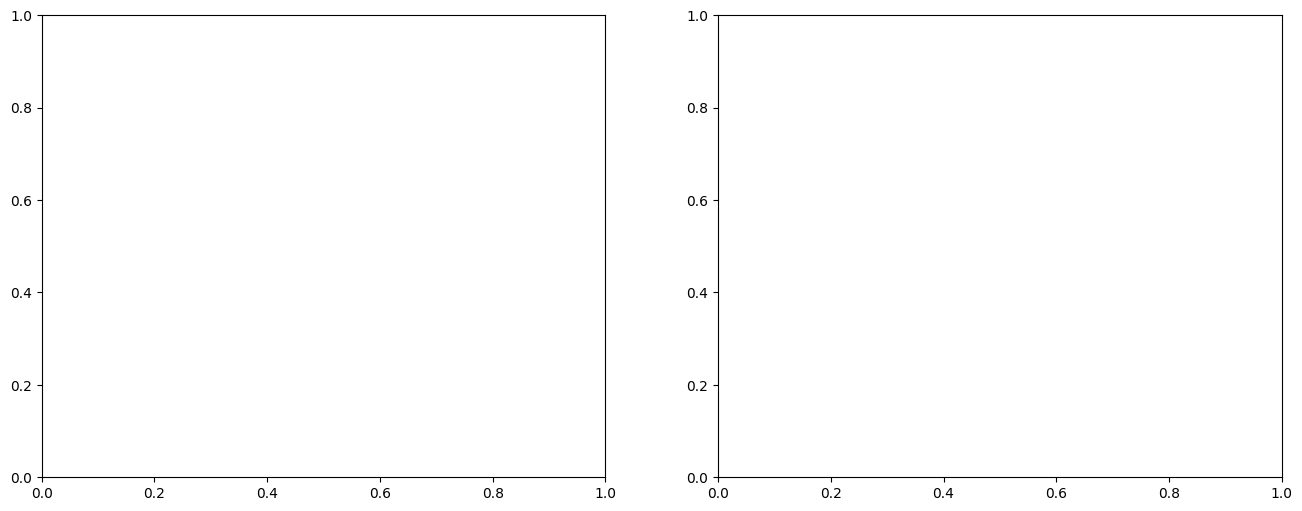

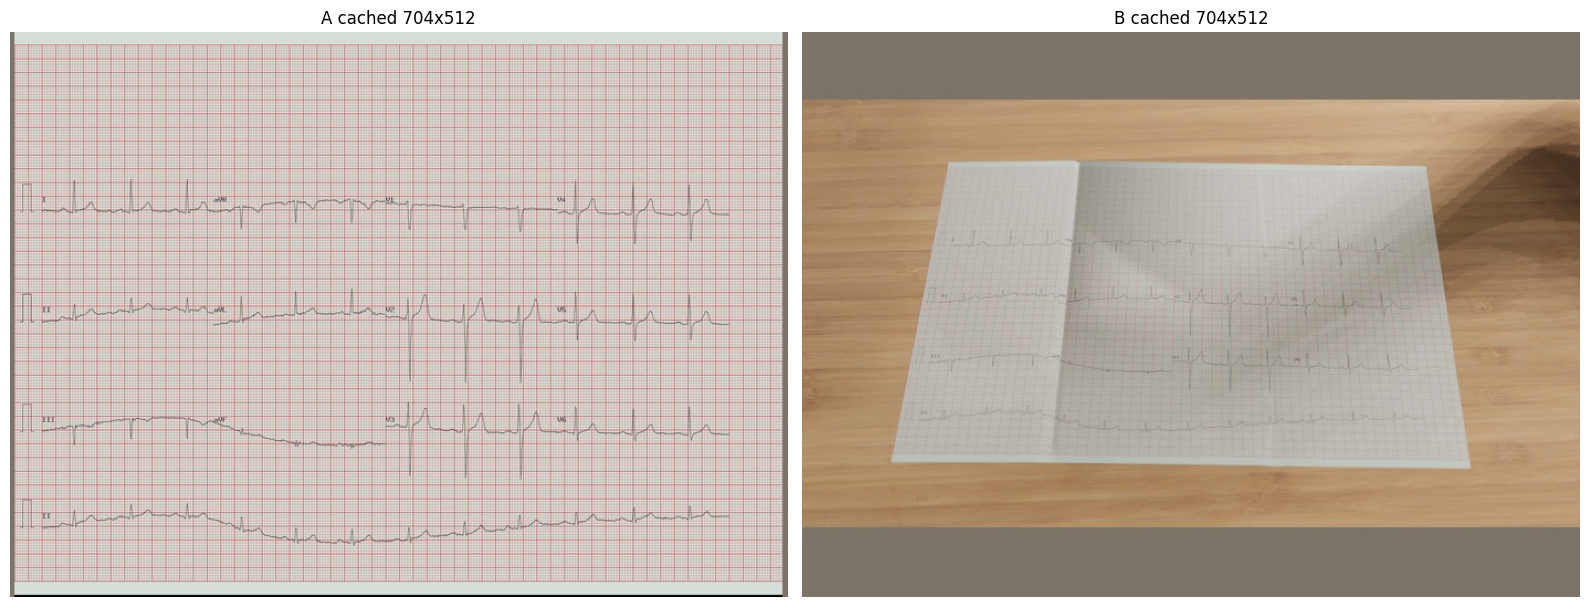

In [ ]:
import pandas as pd, numpy as np
from PIL import Image
from multiprocessing import Pool
from tqdm.auto import tqdm

W, H  = 704, 512
CACHE = f'/content/cache_{W}x{H}'
FILL  = (124, 116, 104)   # ImageNet mean colour: borders become ~0 after normalisation
SUPER = ['NORM', 'MI', 'STTC', 'CD', 'HYP']

labels   = pd.read_csv(f'{DRIVE_ROOT}/labels/labels_genecg.csv', index_col='ecg_id')
subset_B = pd.read_csv(f'{DRIVE_ROOT}/labels/subset_B.csv', index_col='ecg_id')

def letterbox(src, dst):
    # resize keeping the page shape, then pad to exactly W x H (no stretching)
    if os.path.exists(dst):
        return
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    im = Image.open(src).convert('RGB')
    s = min(W / im.width, H / im.height)
    nw, nh = round(im.width * s), round(im.height * s)
    im = im.resize((nw, nh), Image.LANCZOS)   # LANCZOS keeps thin waveform lines
    canvas = Image.new('RGB', (W, H), FILL)
    canvas.paste(im, ((W - nw) // 2, (H - nh) // 2))
    canvas.save(dst, quality=95)

def job(args):
    try:
        letterbox(*args)
        return None
    except Exception as e:
        return f'{args[0]}: {type(e).__name__}: {e}'

jobs  = [(f'{LOCAL_ROOT}/{SUBSET_A}/{r}', f'{CACHE}/A/{r[:-4]}.jpg') for r in labels.rel_path]
jobs += [(f'{LOCAL_ROOT}/B_jpg/{r[:-4]}.jpg', f'{CACHE}/B/{r[:-4]}.jpg') for r in subset_B.rel_path]
print('images to cache:', len(jobs))

t = time.time()
with Pool(os.cpu_count()) as pool:
    errs = [e for e in tqdm(pool.imap_unordered(job, jobs, chunksize=32), total=len(jobs)) if e]
print(f'done in {(time.time()-t)/60:.1f} min | errors: {len(errs)}', errs[:3])

# save the cache to Drive so later sessions skip this step
tar_C = f'{DRIVE_ROOT}/cache_{W}x{H}.tar'
if not os.path.exists(tar_C):
    !tar -cf "{tar_C}" -C /content "cache_{W}x{H}"
!ls -lh "{tar_C}"
!du -sh {CACHE}/*

# quick look: one clean and one photo-like image after resizing
rel = subset_B.rel_path.iloc[0][:-4] + '.jpg'
fig, ax = plt.subplots(1, 2, figsize=(16, 6)) if 'plt' in dir() else (None, None)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, sub in zip(ax, ['A', 'B']):
    a.imshow(Image.open(f'{CACHE}/{sub}/{rel}')); a.set_title(f'{sub} cached {W}x{H}'); a.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, time, glob, torch
import pandas as pd, numpy as np

DRIVE_ROOT = '/content/drive/MyDrive/ecg_v3'
W, H     = 704, 512
CACHE    = f'/content/cache_{W}x{H}'
SUPER    = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
CKPT_DIR = f'{DRIVE_ROOT}/checkpoints'
os.makedirs(CKPT_DIR, exist_ok=True)

print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE: switch runtime to T4 GPU')

# copy the resized images from Drive to the fast local disk
t = time.time()
if not os.path.exists(CACHE):
    !tar -xf "{DRIVE_ROOT}/cache_{W}x{H}.tar" -C /content
print('unpacked in', round(time.time() - t), 's')

# check nothing was cut off when the tar was saved
labels   = pd.read_csv(f'{DRIVE_ROOT}/labels/labels_genecg.csv', index_col='ecg_id')
subset_B = pd.read_csv(f'{DRIVE_ROOT}/labels/subset_B.csv', index_col='ecg_id')
nA = len(glob.glob(f'{CACHE}/A/*/*.jpg'))
nB = len(glob.glob(f'{CACHE}/B/*/*.jpg'))
print(f'A: {nA} / {len(labels)} expected | B: {nB} / {len(subset_B)} expected')
print('CACHE OK' if (nA, nB) == (len(labels), len(subset_B)) else 'CACHE INCOMPLETE: tell me')
!du -sh {CACHE}/*

Mounted at /content/drive
GPU: Tesla T4
unpacked in 120 s
A: 21799 / 21799 expected | B: 7378 / 7378 expected
CACHE OK
3.7G	/content/cache_704x512/A
525M	/content/cache_704x512/B


             n  NORM    MI  STTC    CD   HYP
set                                         
A-train  17084  7596  4379  4186  3907  2119
A-val     2146   955   540   528   495   268
A-test    2158   963   550   521   496   262
B-train   2935  1306   750   727   643   381
B-val     2145   954   540   528   495   268
B-test    2156   962   549   521   496   262
A patient overlap train/val/test: 0 0 0
B patient overlap train/val/test: 0 0 0
loader speed: 141 images/s


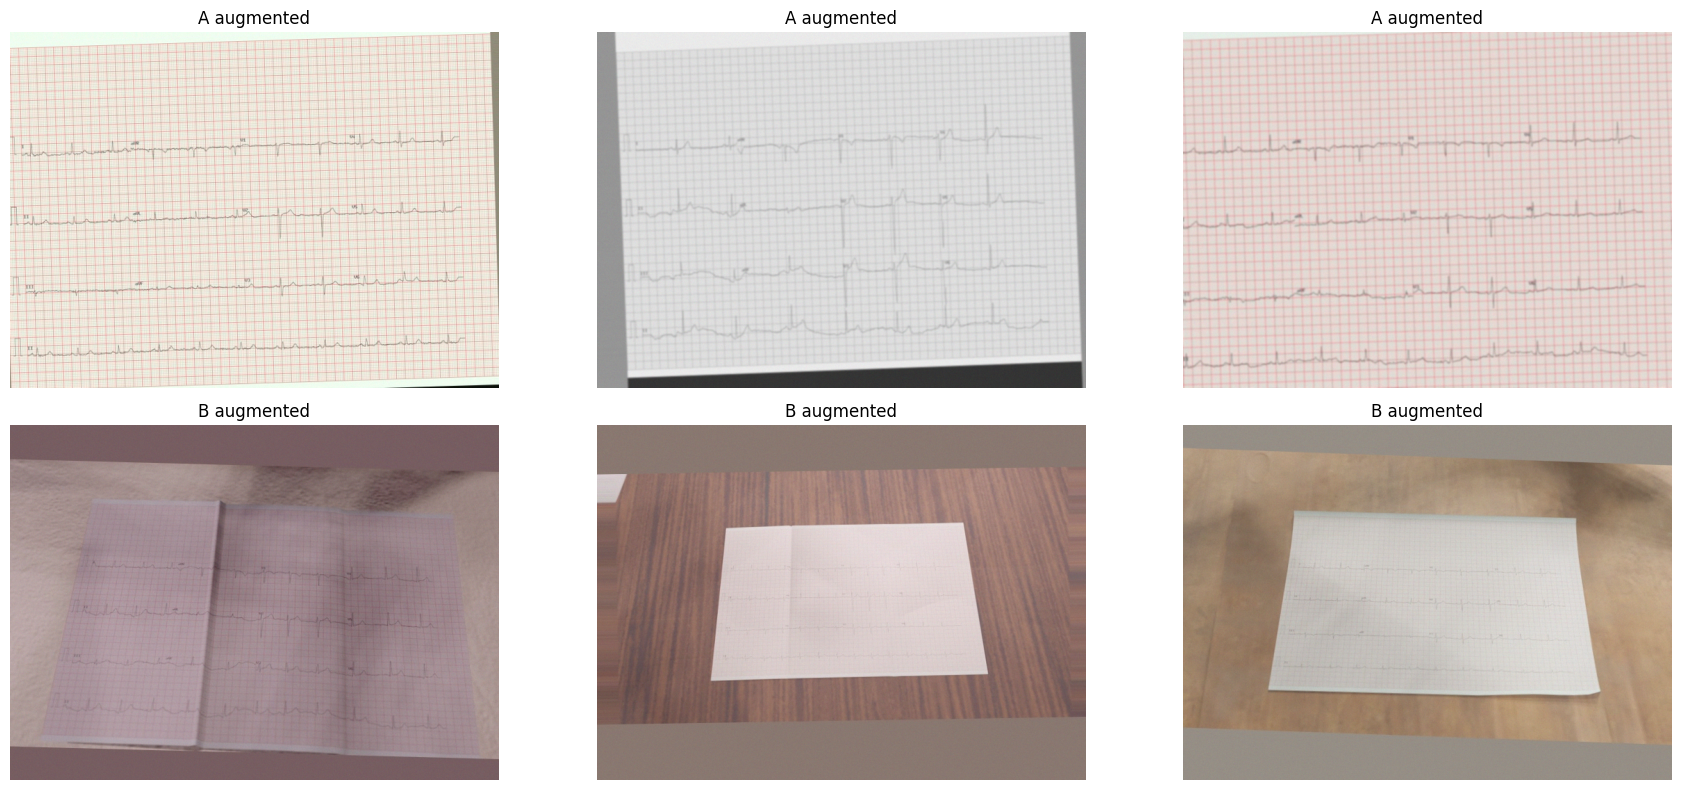

In [ ]:
import math, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision.io import read_image, ImageReadMode

DEVICE = 'cuda'
BS = 16
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

# ---- splits: official PTB-XL patient-level folds (1-8 train, 9 val, 10 test) ----
lab  = labels[labels.n_super > 0]                       # drop ECGs with no superclass
labB = lab.loc[lab.index.intersection(subset_B.index)]
def split(df):
    return {'train': df[df.strat_fold <= 8], 'val': df[df.strat_fold == 9], 'test': df[df.strat_fold == 10]}
SPL = {'A': split(lab), 'B': split(labB)}

rows = []
for sub in ['A', 'B']:
    for sp, df in SPL[sub].items():
        rows.append({'set': f'{sub}-{sp}', 'n': len(df), **{c: int(df[c].sum()) for c in SUPER}})
print(pd.DataFrame(rows).set_index('set').to_string())
# no patient may appear in two splits
for sub in ['A', 'B']:
    p = {sp: set(df.patient_id) for sp, df in SPL[sub].items()}
    print(sub, 'patient overlap train/val/test:', len(p['train'] & p['val']), len(p['train'] & p['test']), len(p['val'] & p['test']))

# ---- dataset: read cached jpg -> uint8 tensor (augmentation runs on GPU) ----
class ECGSet(Dataset):
    def __init__(self, df, sub):
        self.paths = [f'{CACHE}/{sub}/{r[:-4]}.jpg' for r in df.rel_path]
        self.y = torch.tensor(df[SUPER].values, dtype=torch.float32)
        self.ids = df.index.values
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return read_image(self.paths[i], ImageReadMode.RGB), self.y[i]

def make_loader(ds, train):
    return DataLoader(ds, batch_size=BS, shuffle=train, drop_last=train, num_workers=2,
                      pin_memory=True, persistent_workers=True, prefetch_factor=4)

# ---- augmentation on GPU: small tilt/zoom/shift, lighting, grey, blur, noise ----
# no flips: flipping an ECG reverses time and swaps lead positions
def _blur(x, sigma=1.0, k=5):
    t = torch.arange(k, device=x.device, dtype=x.dtype) - k // 2
    g = torch.exp(-t**2 / (2 * sigma**2)); g = g / g.sum()
    x = F.conv2d(F.pad(x, (k//2, k//2, 0, 0), mode='replicate'), g.view(1, 1, 1, k).repeat(3, 1, 1, 1), groups=3)
    x = F.conv2d(F.pad(x, (0, 0, k//2, k//2), mode='replicate'), g.view(1, 1, k, 1).repeat(3, 1, 1, 1), groups=3)
    return x

def gpu_augment(x, max_rot=3.0, max_scale=0.08, max_shift=0.04):
    B, dev = x.shape[0], x.device
    u = lambda: torch.rand(B, device=dev) * 2 - 1
    ang = u() * math.radians(max_rot)
    sc = 1 + u() * max_scale
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([c, -s * H / W, u() * max_shift], 1),
                         torch.stack([s * W / H, c, u() * max_shift], 1)], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode='bilinear', padding_mode='border', align_corners=False)
    b = 1 + u().view(B, 1, 1, 1) * 0.2                    # brightness
    k = 1 + u().view(B, 1, 1, 1) * 0.2                    # contrast
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - m) * k + m * b
    x = x + (torch.rand(B, 3, 1, 1, device=dev) * 2 - 1) * 0.04   # paper/ink tint
    gmask = torch.rand(B, device=dev) < 0.2                        # 20% greyscale
    if gmask.any():
        gray = (0.299 * x[:, 0] + 0.587 * x[:, 1] + 0.114 * x[:, 2]).unsqueeze(1)
        x = torch.where(gmask.view(B, 1, 1, 1), gray.expand_as(x), x)
    bmask = torch.rand(B, device=dev) < 0.2                        # 20% slight blur
    if bmask.any():
        x[bmask] = _blur(x[bmask], sigma=float(torch.empty(1).uniform_(0.5, 1.2)))
    x = x + torch.randn_like(x) * 0.01                             # sensor noise
    return x.clamp_(0, 1)

def to_input(img_u8, train):
    x = img_u8.to(DEVICE, non_blocking=True).float().div_(255)
    if train:
        x = gpu_augment(x)
    x = (x - MEAN) / STD
    return x.contiguous(memory_format=torch.channels_last)

# ---- speed test: can 2 CPU cores feed the GPU fast enough? ----
dl = make_loader(ECGSet(SPL['A']['train'], 'A'), train=True)
it = iter(dl); next(it)
t = time.time(); n = 0
for _ in range(40):
    xb, yb = next(it); _ = to_input(xb, True); n += len(xb)
torch.cuda.synchronize()
print(f'loader speed: {n / (time.time() - t):.0f} images/s')

# ---- look at augmented samples (3 clean A, 3 photo-like B) ----
xa = torch.stack([ECGSet(SPL['A']['train'], 'A')[i][0] for i in range(3)])
xb = torch.stack([ECGSet(SPL['B']['train'], 'B')[i][0] for i in range(3)])
aug = gpu_augment(torch.cat([xa, xb]).to(DEVICE).float() / 255).cpu()
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
for a, img, ttl in zip(ax.flat, aug, ['A'] * 3 + ['B'] * 3):
    a.imshow(img.permute(1, 2, 0)); a.set_title(f'{ttl} augmented'); a.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
def to_input(img_u8, train):
    # augmentation always in full precision, even if called inside autocast
    with torch.autocast('cuda', enabled=False):
        x = img_u8.to(DEVICE, non_blocking=True).float().div_(255)
        if train:
            x = gpu_augment(x)
        x = (x - MEAN) / STD
    return x.contiguous(memory_format=torch.channels_last)

In [ ]:
import timm, gc
from torch.amp import autocast, GradScaler
torch.backends.cudnn.benchmark = True

ARCHS = {'convnext_tiny': 'convnext_tiny.fb_in22k_ft_in1k',   # main model (ImageNet-22k pretrained)
         'resnet18':      'resnet18.tv_in1k'}                   # baseline (same family as the old model)

def build_model(arch, pretrained=True):
    m = timm.create_model(ARCHS[arch], pretrained=pretrained, num_classes=len(SUPER),
                          drop_path_rate=0.1 if 'convnext' in arch else 0.0)
    return m.to(DEVICE).to(memory_format=torch.channels_last)

def probe(arch, bs=BS, grad_ckpt=False):
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    m = build_model(arch); m.train()
    if grad_ckpt: m.set_grad_checkpointing(True)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4); scaler = GradScaler()
    x = torch.randint(0, 255, (bs, 3, H, W), dtype=torch.uint8)
    y = torch.randint(0, 2, (bs, len(SUPER))).float().to(DEVICE)
    times = []
    try:
        for _ in range(8):
            torch.cuda.synchronize(); t = time.time()
            with autocast('cuda', dtype=torch.float16):
                loss = F.binary_cross_entropy_with_logits(m(to_input(x, True)), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            torch.cuda.synchronize(); times.append(time.time() - t)
        ips = bs / np.mean(times[3:])
        mem = torch.cuda.max_memory_allocated() / 1e9
        n_tr = len(SPL['A']['train'])
        print(f'{arch:14s} bs={bs} grad_ckpt={grad_ckpt}: {ips:5.1f} img/s | peak GPU mem {mem:4.1f} GB '
              f'| ~{n_tr / ips / 60:.1f} min per epoch on A-train | params {sum(p.numel() for p in m.parameters())/1e6:.1f}M')
        ok = True
    except torch.cuda.OutOfMemoryError:
        print(f'{arch:14s} bs={bs} grad_ckpt={grad_ckpt}: OUT OF MEMORY'); ok = False
    del m, opt; gc.collect(); torch.cuda.empty_cache()
    return ok

if not probe('convnext_tiny'):
    probe('convnext_tiny', grad_ckpt=True)
probe('resnet18')

convnext_tiny  bs=16 grad_ckpt=False:  30.0 img/s | peak GPU mem  8.2 GB | ~9.5 min per epoch on A-train | params 27.8M


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

resnet18       bs=16 grad_ckpt=False: 118.9 img/s | peak GPU mem  2.0 GB | ~2.4 min per epoch on A-train | params 11.2M


True

In [ ]:
import shutil
from sklearn.metrics import roc_auc_score, f1_score

@torch.no_grad()
def predict(model, ds):
    model.eval()
    dl = DataLoader(ds, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
    out = []
    for xb, _ in dl:
        with autocast('cuda', dtype=torch.float16):
            out.append(model(to_input(xb, False)).float().cpu())
    return torch.cat(out), ds.y

def metrics(logits, y):
    p, y = torch.sigmoid(logits).numpy(), y.numpy()
    aucs = [roc_auc_score(y[:, i], p[:, i]) for i in range(y.shape[1])]
    f1 = f1_score(y, p > 0.5, average='macro', zero_division=0)
    return float(np.mean(aucs)), aucs, float(f1)

def save_atomic(obj, path):
    # write locally first, then copy, so a disconnect never leaves a half-written file on Drive
    tmp = '/content/_tmp.pth'
    torch.save(obj, tmp)
    shutil.copyfile(tmp, path + '.part'); os.replace(path + '.part', path)

def train_run(name, arch, train_ds, val_sets, select_on, epochs, lr, wd=0.05,
              init_from=None, patience=4, warmup_steps=500, log_every=200):
    last_p, best_p = f'{CKPT_DIR}/{name}_last.pth', f'{CKPT_DIR}/{name}_best.pth'
    model = build_model(arch, pretrained=init_from is None)
    if init_from:
        model.load_state_dict(torch.load(init_from, map_location=DEVICE, weights_only=False)['model'])
        print('initialised from', init_from)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    dl = make_loader(train_ds, train=True)
    total = epochs * len(dl)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warmup_steps) * 0.5 * (1 + math.cos(math.pi * min(s, total) / total)))
    scaler = GradScaler()
    start, best, bad, hist = 0, -1.0, 0, []
    if os.path.exists(last_p):
        ck = torch.load(last_p, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
        sched.load_state_dict(ck['sched']); scaler.load_state_dict(ck['scaler'])
        start, best, bad, hist = ck['epoch'], ck['best'], ck['bad'], ck['hist']
        print(f'resumed {name}: {start} epochs done, best val AUROC {best:.4f}')
    if start >= epochs or bad >= patience:
        print(f'{name} already finished'); return pd.DataFrame(hist)
    print(f'{name}: {len(train_ds)} train images, {len(dl)} steps/epoch, epochs {start + 1}..{epochs}')

    for ep in range(start, epochs):
        model.train(); t0 = time.time(); run, n = 0.0, 0
        for i, (xb, yb) in enumerate(dl):
            x, y = to_input(xb, True), yb.to(DEVICE, non_blocking=True)
            with autocast('cuda', dtype=torch.float16):
                logits = model(x)
            loss = F.binary_cross_entropy_with_logits(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.item(); n += 1
            if i % log_every == 0:
                print(f'  ep {ep + 1} step {i}/{len(dl)} loss {run / n:.4f} '
                      f'({(i + 1) * BS / (time.time() - t0):.0f} img/s)', flush=True)
        row = {'epoch': ep + 1, 'train_loss': round(run / n, 4),
               'lr': f"{opt.param_groups[0]['lr']:.2e}", 'train_min': round((time.time() - t0) / 60, 1)}
        for vn, vds in val_sets.items():
            auc, aucs, f1 = metrics(*predict(model, vds))
            row[f'{vn}_auc'], row[f'{vn}_f1'] = round(auc, 4), round(f1, 4)
            row.update({f'{vn}_{c}': round(a, 3) for c, a in zip(SUPER, aucs)})
        score = float(np.mean([row[f'{v}_auc'] for v in select_on]))
        if score > best:
            best, bad = score, 0
            save_atomic({'model': model.state_dict(), 'arch': arch, 'timm_name': ARCHS[arch],
                         'classes': SUPER, 'input_wh': (W, H), 'epoch': ep + 1, 'val_auc': score}, best_p)
            row['saved_best'] = True
        else:
            bad += 1
        hist.append(row)
        save_atomic({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                     'scaler': scaler.state_dict(), 'epoch': ep + 1, 'best': best, 'bad': bad, 'hist': hist}, last_p)
        pd.DataFrame(hist).to_csv(f'{CKPT_DIR}/{name}_history.csv', index=False)
        print(' | '.join(f'{k} {v}' for k, v in row.items() if not any(k.endswith('_' + c) for c in SUPER)), flush=True)
        if bad >= patience:
            print(f'early stop: no improvement for {patience} epochs'); break
    print(f'{name} done. best val AUROC {best:.4f} -> {best_p}')
    return pd.DataFrame(hist)

# ---- stage 1: ConvNeXt-Tiny on clean A; best epoch picked on A-val only ----
hist_s1 = train_run('convnext_s1_A', 'convnext_tiny',
                    ECGSet(SPL['A']['train'], 'A'),
                    {'A_val': ECGSet(SPL['A']['val'], 'A'), 'B_val': ECGSet(SPL['B']['val'], 'B')},
                    select_on=['A_val'], epochs=10, lr=1e-4)

convnext_s1_A: 17084 train images, 1067 steps/epoch, epochs 1..10
  ep 1 step 0/1067 loss 0.6785 (12 img/s)
  ep 1 step 200/1067 loss 0.5680 (27 img/s)
  ep 1 step 400/1067 loss 0.5534 (28 img/s)
  ep 1 step 600/1067 loss 0.5101 (28 img/s)
  ep 1 step 800/1067 loss 0.4782 (28 img/s)
  ep 1 step 1000/1067 loss 0.4551 (28 img/s)
epoch 1 | train_loss 0.4482 | lr 9.76e-05 | train_min 10.2 | A_val_auc 0.891 | A_val_f1 0.6404 | B_val_auc 0.8168 | B_val_f1 0.4782 | saved_best True
  ep 2 step 0/1067 loss 0.3825 (19 img/s)
  ep 2 step 200/1067 loss 0.3389 (28 img/s)
  ep 2 step 400/1067 loss 0.3312 (28 img/s)
  ep 2 step 600/1067 loss 0.3239 (28 img/s)
  ep 2 step 800/1067 loss 0.3192 (28 img/s)
  ep 2 step 1000/1067 loss 0.3144 (28 img/s)
epoch 2 | train_loss 0.3139 | lr 9.05e-05 | train_min 10.3 | A_val_auc 0.9191 | A_val_f1 0.6987 | B_val_auc 0.8158 | B_val_f1 0.3893 | saved_best True
  ep 3 step 0/1067 loss 0.2900 (21 img/s)
  ep 3 step 200/1067 loss 0.2840 (29 img/s)
  ep 3 step 400/1067 

In [ ]:
from torch.utils.data import WeightedRandomSampler

# ---- per-class AUROC of the stage-1 best epoch ----
h1 = pd.read_csv(f'{CKPT_DIR}/convnext_s1_A_history.csv')
b = h1.loc[h1.A_val_auc.idxmax()]
print(f'stage 1 best = epoch {int(b.epoch)}')
print(pd.DataFrame({v: [b[f'{v}_{c}'] for c in SUPER] for v in ['A_val', 'B_val']}, index=SUPER).T.to_string(), '\n')

# ---- loader that can mix two datasets 50/50 each epoch ----
def make_loader(ds, train):
    kw = dict(batch_size=BS, num_workers=2, pin_memory=True, persistent_workers=True, prefetch_factor=4)
    if train and hasattr(ds, 'sample_weights'):
        sampler = WeightedRandomSampler(ds.sample_weights, num_samples=ds.epoch_size, replacement=True)
        return DataLoader(ds, sampler=sampler, drop_last=True, **kw)
    return DataLoader(ds, shuffle=train, drop_last=train, **kw)

dsB, dsA = ECGSet(SPL['B']['train'], 'B'), ECGSet(SPL['A']['train'], 'A')
mix = ConcatDataset([dsB, dsA])
# half of every batch is a photo, half a clean scan (so the model keeps what it learned in stage 1)
mix.sample_weights = torch.cat([torch.full((len(dsB),), 0.5 / len(dsB)),
                                torch.full((len(dsA),), 0.5 / len(dsA))]).double()
mix.epoch_size = 2 * len(dsB)            # ~5,870 images per epoch, ~4.5 min incl. validation

# ---- stage 2: start from stage-1 best, lower learning rate, pick epoch on mean of A_val and B_val ----
hist_s2 = train_run('convnext_s2_AB', 'convnext_tiny', mix,
                    {'A_val': ECGSet(SPL['A']['val'], 'A'), 'B_val': ECGSet(SPL['B']['val'], 'B')},
                    select_on=['A_val', 'B_val'], epochs=12, lr=5e-5,
                    init_from=f'{CKPT_DIR}/convnext_s1_A_best.pth',
                    warmup_steps=100, log_every=100)

stage 1 best = epoch 8
        NORM     MI   STTC     CD    HYP
A_val  0.953  0.939  0.938  0.947  0.907
B_val  0.890  0.867  0.870  0.844  0.755 

initialised from /content/drive/MyDrive/ecg_v3/checkpoints/convnext_s1_A_best.pth
convnext_s2_AB: 20019 train images, 366 steps/epoch, epochs 1..12
  ep 1 step 0/366 loss 0.2848 (13 img/s)
  ep 1 step 100/366 loss 0.3020 (27 img/s)
  ep 1 step 200/366 loss 0.2881 (27 img/s)
  ep 1 step 300/366 loss 0.2801 (28 img/s)
epoch 1 | train_loss 0.2763 | lr 4.91e-05 | train_min 3.5 | A_val_auc 0.9348 | A_val_f1 0.7452 | B_val_auc 0.9104 | B_val_f1 0.6803 | saved_best True
  ep 2 step 0/366 loss 0.2873 (20 img/s)
  ep 2 step 100/366 loss 0.2678 (27 img/s)
  ep 2 step 200/366 loss 0.2640 (28 img/s)
  ep 2 step 300/366 loss 0.2599 (28 img/s)
epoch 2 | train_loss 0.2588 | lr 4.67e-05 | train_min 3.5 | A_val_auc 0.9327 | A_val_f1 0.7383 | B_val_auc 0.9157 | B_val_f1 0.7097 | saved_best True
  ep 3 step 0/366 loss 0.2110 (21 img/s)
  ep 3 step 100/366 los